# Démonstration Cartomize — Sentinel-2 L2A réel

**Objectif :** partir de vraies bandes téléchargées, contrôler leur provenance, lancer le prétraitement automatique, calculer des indices spectraux et produire des statistiques vérifiables.

Aucune image synthétique et aucun résultat prédéfini ne sont utilisés. L'identifiant exact de la scène est lu dans `data/provenance.json`.

> L'emprise est une fenêtre d'analyse située à Kinshasa et non une limite administrative.

## 1. Préparer l'environnement

Le dossier `data` est produit par `download_real_data.py`. Dans la version validée sur GitHub, les fichiers téléchargés et leurs SHA-256 sont conservés avec le tutoriel.

In [1]:
from pathlib import Path
import json, shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
import cartomize as cm

ROOT = Path.cwd()
if ROOT.name != "demonstration-carto":
    candidate = ROOT / "demonstration-carto"
    if candidate.is_dir():
        ROOT = candidate
DATA = ROOT / "data"
RESULTS = ROOT / "results"
if not (DATA / "provenance.json").is_file():
    raise FileNotFoundError("Données réelles absentes : exécuter download_real_data.py avant le notebook.")
if RESULTS.exists():
    shutil.rmtree(RESULTS)
RESULTS.mkdir()
provenance = json.loads((DATA / "provenance.json").read_text(encoding="utf-8"))
print("Scène :", provenance["selected_item_id"])
print("Date :", provenance["selected_datetime"])
print("Plateforme :", provenance["platform"])
print("Tuile MGRS :", provenance["mgrs_tile"])
print("Nuages déclarés :", provenance["global_cloud_cover_percent"], "%")
print("Pixels SCL utilisables sur l'emprise :", round(provenance["aoi_scl_usable_percent_before_processing"], 2), "%")

Scène : S2B_33MWR_20240720_0_L2A
Date : 2024-07-20T09:21:50.068000Z
Plateforme : sentinel-2b
Tuile MGRS : None
Nuages déclarés : 9.286346 %
Pixels SCL utilisables sur l'emprise : 99.95 %


## 2. Contrôler les fichiers avant traitement

On vérifie le CRS, la résolution, le type de pixel et les paramètres de calibration réellement déclarés dans le manifeste Cartomize.

In [2]:
scene = cm.load_scenes_manifest(DATA / "scenes.json")[0]
rows = []
for name, band in scene.bands.items():
    with rasterio.open(band.path) as src:
        rows.append({
            "bande": name,
            "fichier": Path(band.path).name,
            "largeur": src.width,
            "hauteur": src.height,
            "crs": str(src.crs),
            "resolution": src.res,
            "dtype": src.dtypes[0],
            "scale": band.scale,
            "offset": band.offset,
            "unite": band.unit,
        })
display(pd.DataFrame(rows))
print("Masque qualité :", Path(scene.quality).name, "|", scene.quality_kind)
print("Notes de calibration :")
for note in scene.notes:
    print("-", note)

,bande,fichier,largeur,hauteur,crs,resolution,dtype,scale,offset,unite
0,blue,B02.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
1,green,B03.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
2,red,B04.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance
3,nir,B08.tif,667,664,EPSG:32733,"(10.0, 10.0)",uint16,0.0001,0.0,reflectance


Masque qualité : SCL.tif | sentinel_scl
Notes de calibration :
- Earth Search COG harmonisé blue : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé green : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé red : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.
- Earth Search COG harmonisé nir : scale déclaré=0.0001, offset déclaré=-0.1, offset effectif=0 ; earthsearch:boa_offset_applied=true, aucune seconde application du décalage BOA.


## 3. Prétraitement automatique

Cartomize contrôle la couverture, applique la calibration déclarée, utilise la couche SCL, harmonise les grilles et découpe sur la zone d'étude. Le seuil de démonstration est fixé à 95 % avant de connaître le résultat final.

In [3]:
prepared = cm.preprocess_imagery(
    DATA,
    RESULTS / "preprocessed",
    aoi=DATA / "aoi.geojson",
    band_order=["blue", "green", "red", "nir"],
    coverage_threshold=95,
    allow_partial=False,
    mask_clouds=True,
    mask_saturation=False,
    multiband=True,
    separate_bands=True,
    composition="natural",
)
print("Statut :", prepared.report["status"])
print("Scènes retenues :", prepared.report["selected_scene_ids"])
print("Couverture utile :", round(prepared.report["usable_percent"], 3), "%")
print("Mosaïque :", prepared.report["mosaic"])
print("Rapport :", prepared.manifest)
product = prepared.products[0]
display(pd.DataFrame([product]))

Statut : partial
Scènes retenues : ['S2B_33MWR_20240720_0_L2A']
Couverture utile : 99.953 %
Mosaïque : False
Rapport : /home/runner/work/cartomize-python/cartomize-python/demonstration-carto/results/preprocessed/preprocessing.json


,scenes,multiband,bands,composition,source_index,report
0,[S2B_33MWR_20240720_0_L2A],/home/runner/work/cartomize-python/cartomize-p...,"{'1': {'name': 'blue', 'path': '/home/runner/w...",/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...,/home/runner/work/cartomize-python/cartomize-p...


## 4. Composition en couleurs naturelles

La composition est un produit de visualisation. Les analyses suivantes utilisent toujours le raster scientifique multibande.

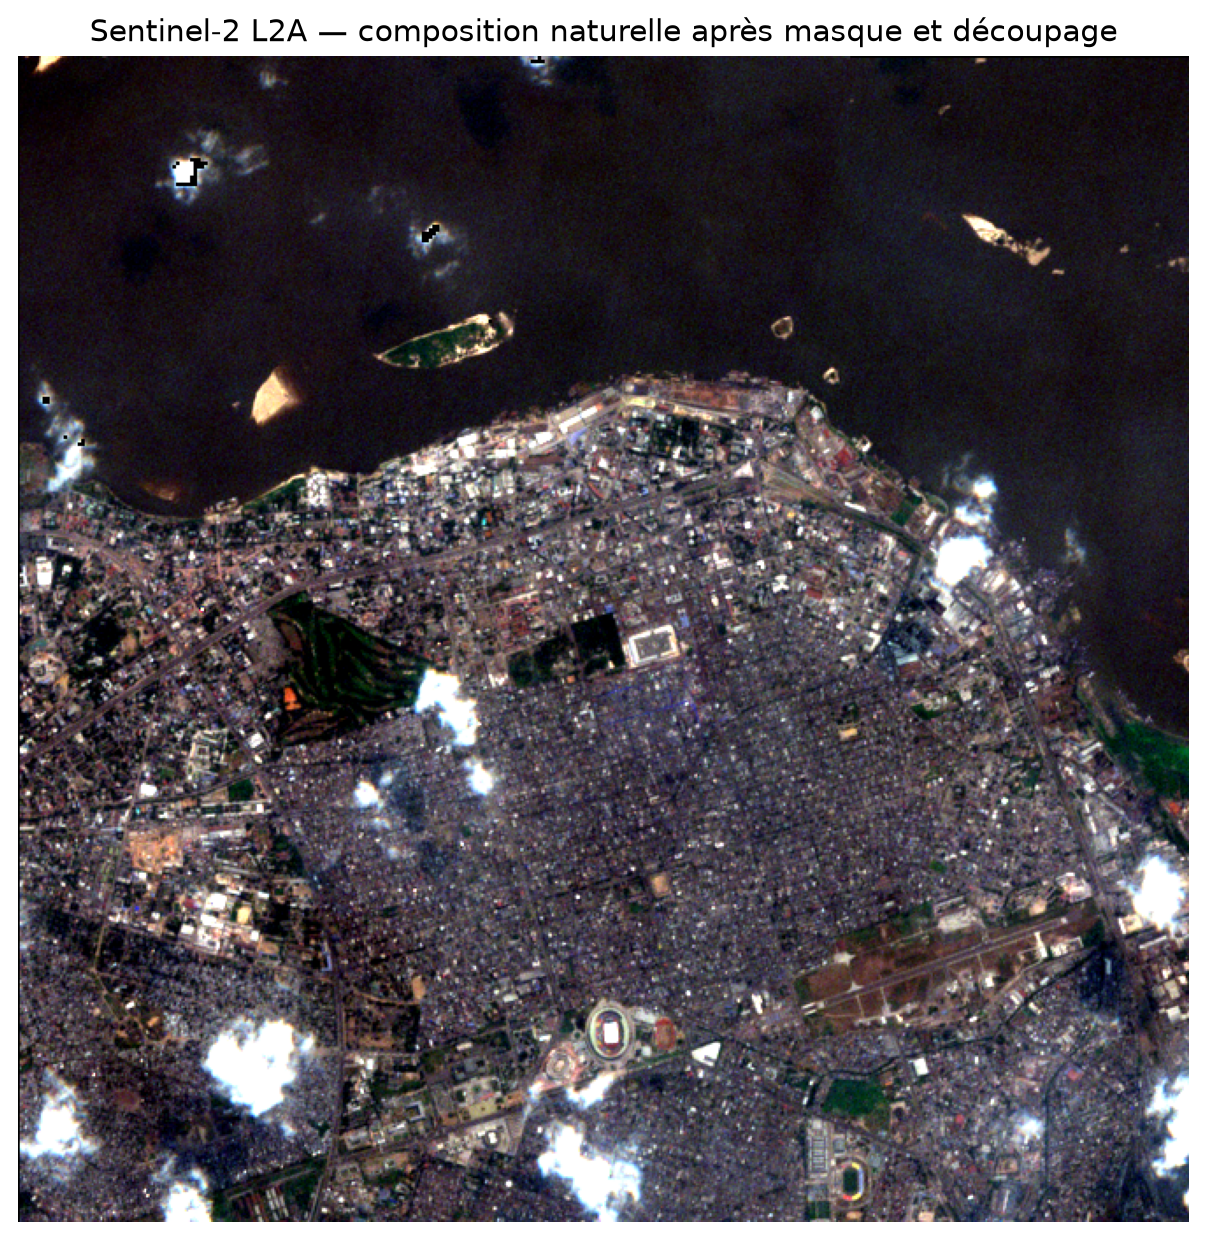

In [4]:
composition = Path(product["composition"])
with rasterio.open(composition) as src:
    rgb = np.moveaxis(src.read()[:3], 0, -1)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(rgb)
ax.set_title("Sentinel-2 L2A — composition naturelle après masque et découpage")
ax.axis("off")
fig.tight_layout()
fig.savefig(RESULTS / "natural_color.png", dpi=180, bbox_inches="tight")
plt.show()
display(IPImage(filename=str(RESULTS / "natural_color.png")))


## 5. Indices spectraux

Calcul de trois indices à partir de la réflectance de surface calibrée :

- NDVI : végétation ;
- NDWI (McFeeters) : contraste eau / proche infrarouge ;
- EVI : végétation avec correction par le bleu et constante additive.

Les formules et références sont celles du registre Cartomize.

In [5]:
indices_path = cm.spectral_indices(
    product["multiband"],
    RESULTS / "indices.tif",
    indices=["NDVI", "NDWI", "EVI"],
)
definitions = {row["name"]: row for row in cm.list_indices()}
display(pd.DataFrame([
    {"indice": name, "formule": definitions[name]["formula"], "reference": definitions[name]["reference"]}
    for name in ("NDVI", "NDWI", "EVI")
]))

,indice,formule,reference
0,NDVI,(nir-red)/(nir+red),https://ntrs.nasa.gov/citations/19740022614
1,NDWI,(green-nir)/(green+nir),https://doi.org/10.1080/01431169608948714
2,EVI,g*(nir-red)/(nir+C1*red-C2*blue+L),https://doi.org/10.1016/S0034-4257(96)00112-5


,count,min,max,mean,std,p05,p50,p95
NDVI,441823.0,-0.373441,0.826395,0.090253,0.186505,-0.161707,0.113782,0.430157
NDWI,441823.0,-0.998533,0.375274,-0.220408,0.175803,-0.519501,-0.248574,0.032505
EVI,441823.0,-0.122345,0.769383,0.053566,0.085229,-0.039066,0.050113,0.211033


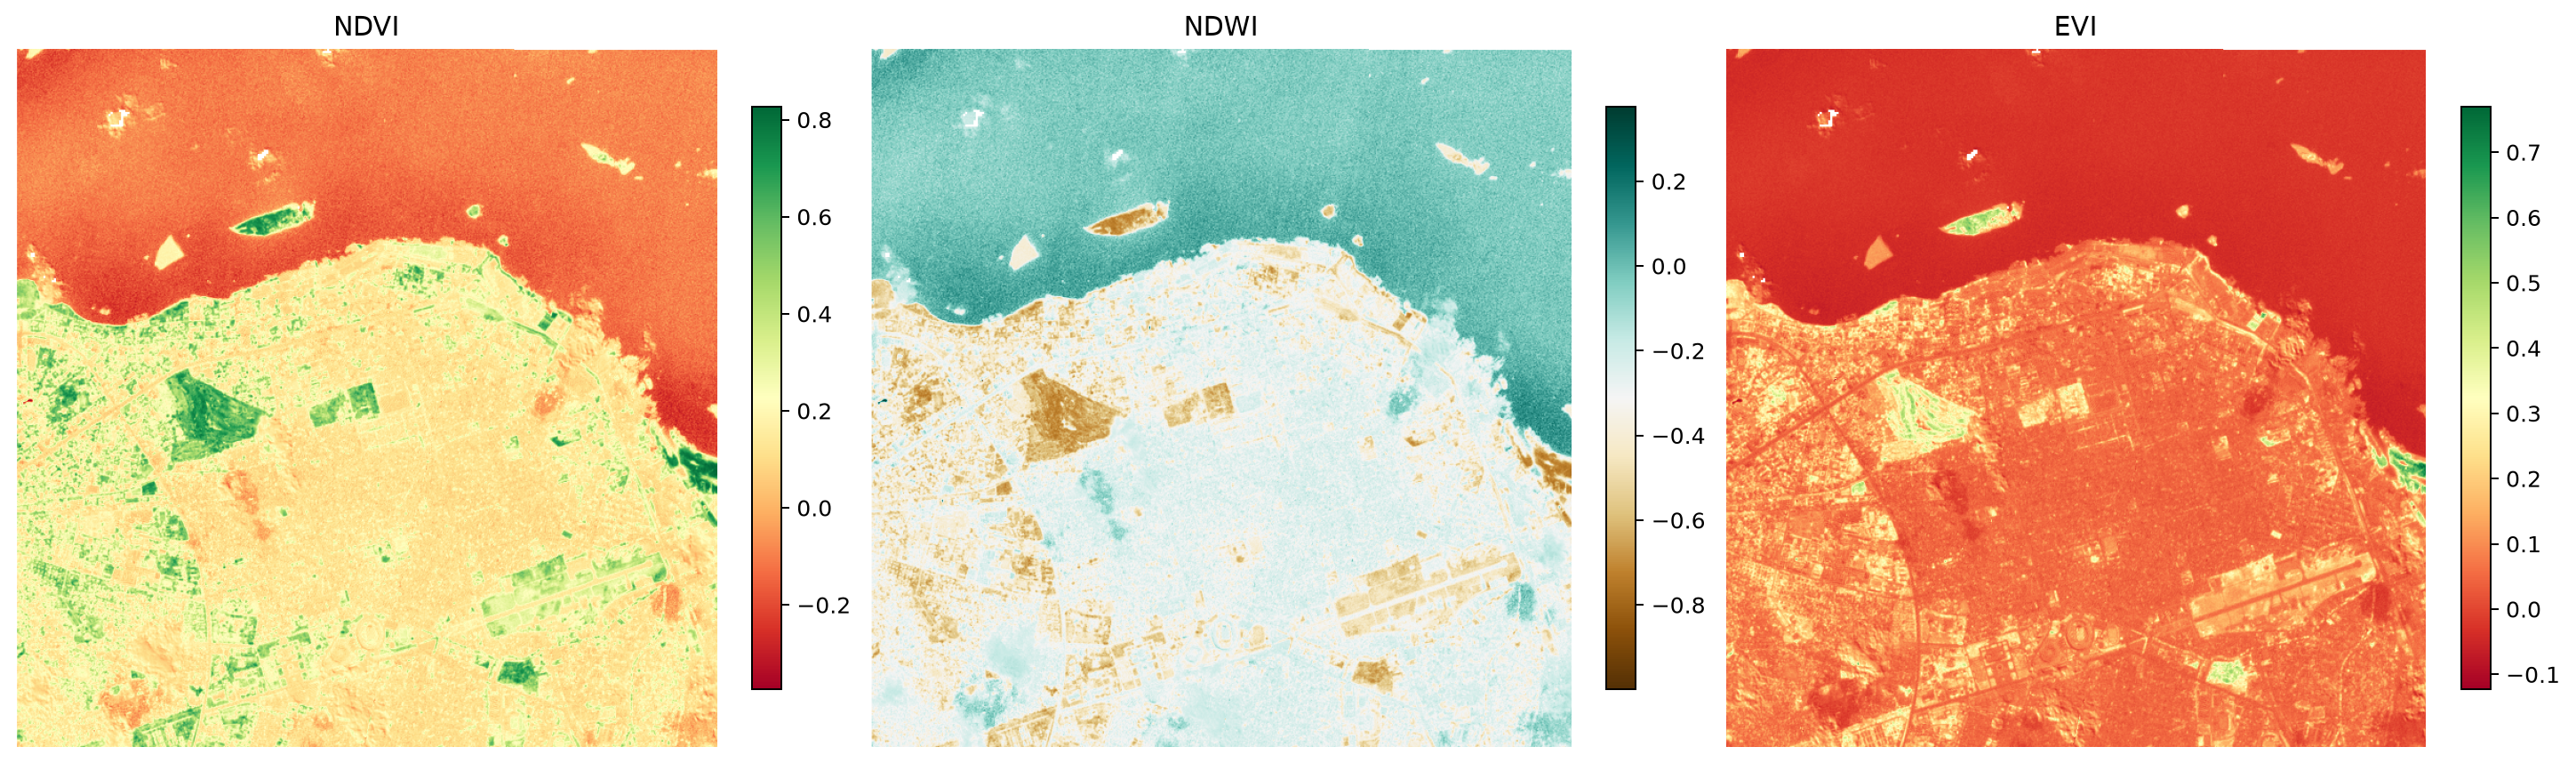

In [6]:
stats = {}
with rasterio.open(indices_path) as src:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for band, name in enumerate(src.descriptions, 1):
        data = src.read(band, masked=True).astype("float64")
        valid = data.compressed()
        stats[name] = {
            "count": int(valid.size),
            "min": float(valid.min()),
            "max": float(valid.max()),
            "mean": float(valid.mean()),
            "std": float(valid.std()),
            "p05": float(np.quantile(valid, .05)),
            "p50": float(np.quantile(valid, .50)),
            "p95": float(np.quantile(valid, .95)),
        }
        view = axes[band-1].imshow(data, cmap="RdYlGn" if name != "NDWI" else "BrBG")
        axes[band-1].set_title(name)
        axes[band-1].axis("off")
        fig.colorbar(view, ax=axes[band-1], shrink=.75)
    fig.savefig(RESULTS / "indices.png", dpi=180, bbox_inches="tight")
display(pd.DataFrame(stats).T)
plt.show()
display(IPImage(filename=str(RESULTS / "indices.png")))


## 6. Statistiques zonales NDVI

On utilise le polygone d'étude comme zone et le premier canal du raster d'indices, qui correspond à NDVI.

In [7]:
zonal = cm.raster.zonal_stats(
    indices_path,
    DATA / "aoi.geojson",
    band=1,
    prefix="ndvi_",
    include_coverage=True,
)
zonal.to_file(RESULTS / "ndvi_zonal.gpkg", driver="GPKG", index=False)
pd.DataFrame(zonal.drop(columns=zonal.geometry.name)).to_csv(RESULTS / "ndvi_zonal.csv", index=False)
display(zonal.drop(columns=zonal.geometry.name))

,name,scope,ndvi_count,ndvi_min,ndvi_max,ndvi_mean,ndvi_sum,ndvi_std,ndvi_zone_pixels,ndvi_raster_pixels,ndvi_coverage_percent
0,Fenêtre de démonstration Kinshasa,emprise d'analyse; pas une limite administrative,441823,-0.373441,0.826395,0.090253,39875.755335,0.186505,442031,442031,99.952944


## 7. Bilan réel de la couche SCL

Les codes SCL restent ceux du produit Sentinel-2 L2A. Ils ne sont pas renommés en classes d'occupation du sol.

,code,classe_SCL,pixels,percent,area_ha
0,4,Vegetation,15,0.013581,0.60
1,5,Not vegetated,69107,62.570283,2764.28
2,6,Water,41226,37.326500,1649.04
3,7,Unclassified,47,0.042554,1.88
4,8,Cloud medium probability,52,0.047081,2.08


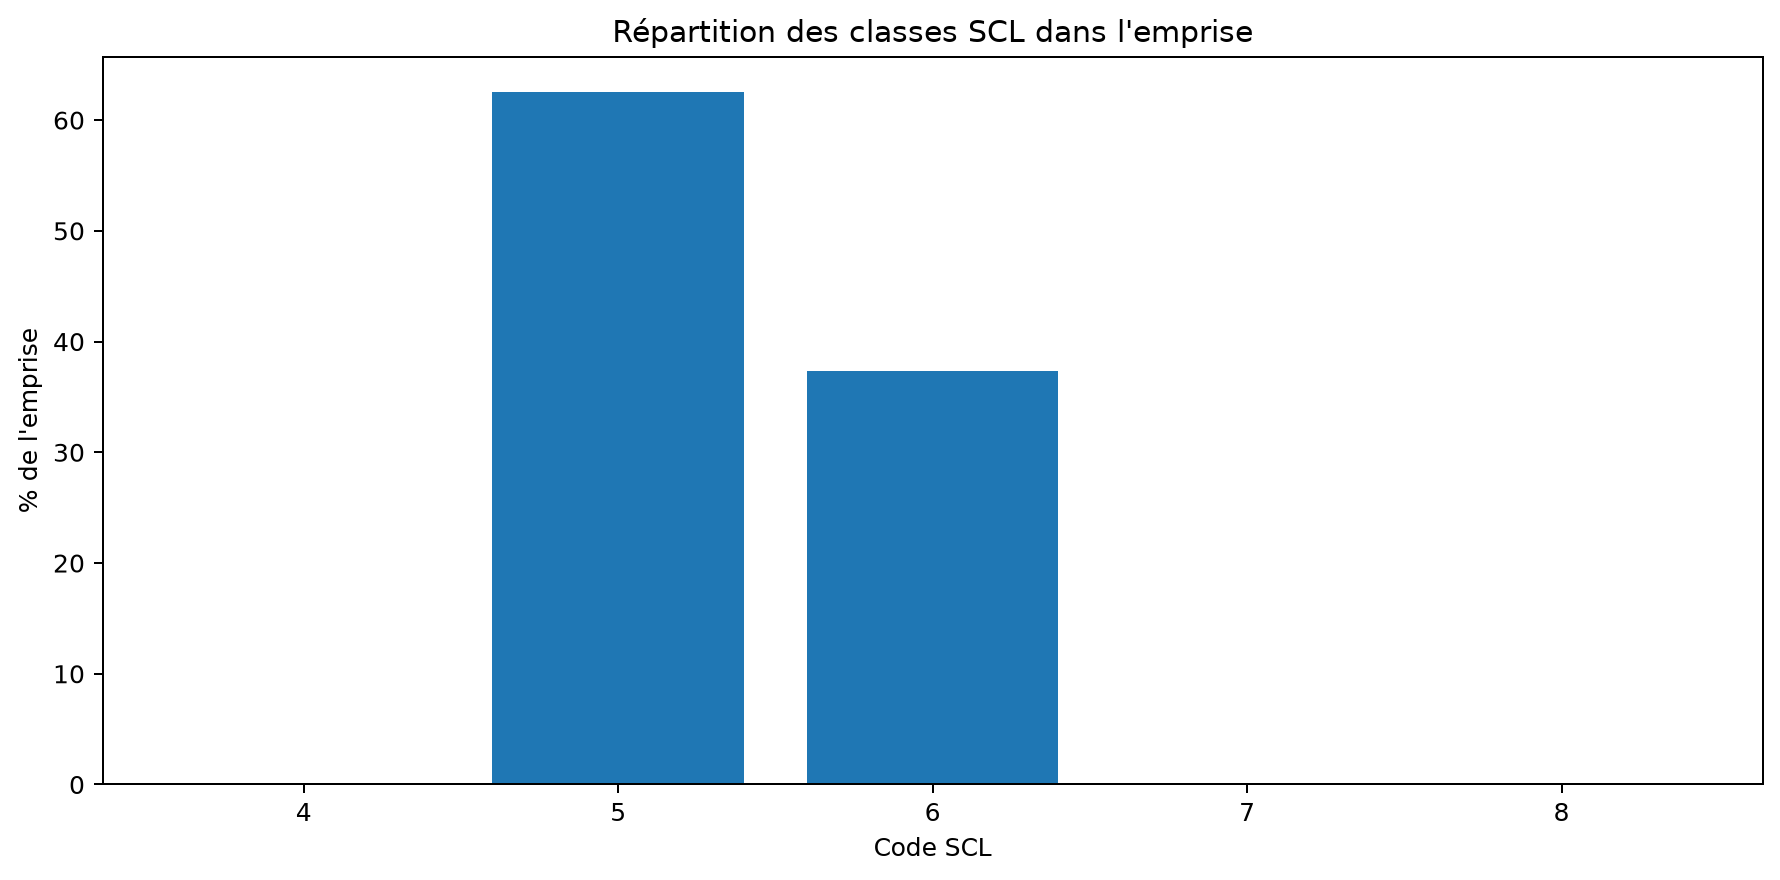

In [8]:
SCL_LABELS = {
    0: "No Data",
    1: "Saturated or defective",
    2: "Dark area pixels",
    3: "Cloud shadows",
    4: "Vegetation",
    5: "Not vegetated",
    6: "Water",
    7: "Unclassified",
    8: "Cloud medium probability",
    9: "Cloud high probability",
    10: "Thin cirrus",
    11: "Snow or ice",
}
aoi = gpd.read_file(DATA / "aoi.geojson")
with rasterio.open(DATA / "SCL.tif") as src:
    geom = [g.__geo_interface__ for g in aoi.to_crs(src.crs).geometry]
    arr, transform = mask(src, geom, crop=True, filled=False, indexes=1)
    values = arr.compressed().astype("int32")
    unique, counts = np.unique(values, return_counts=True)
    pixel_area_ha = abs(transform.a * transform.e) / 10000.0
scl = []
for value, count in zip(unique, counts):
    scl.append({
        "code": int(value),
        "classe_SCL": SCL_LABELS.get(int(value), f"Code {value}"),
        "pixels": int(count),
        "percent": float(100 * count / counts.sum()),
        "area_ha": float(count * pixel_area_ha),
    })
scl_df = pd.DataFrame(scl)
scl_df.to_csv(RESULTS / "scl_summary.csv", index=False)
display(scl_df)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(scl_df["code"].astype(str), scl_df["percent"])
ax.set_xlabel("Code SCL")
ax.set_ylabel("% de l'emprise")
ax.set_title("Répartition des classes SCL dans l'emprise")
fig.tight_layout()
fig.savefig(RESULTS / "scl.png", dpi=180, bbox_inches="tight")
plt.show()
display(IPImage(filename=str(RESULTS / "scl.png")))


## 8. Ce que nous ne faisons pas

Aucune classification supervisée n'est lancée ici : nous n'avons pas de données de vérité terrain indépendantes pour cette scène. Une classification non supervisée peut regrouper des signatures spectrales, mais les groupes ne doivent pas être interprétés comme des classes d'occupation du sol sans validation.

## 9. Enregistrer les résultats reproductibles

Le fichier `metrics.json` est généré à partir des résultats de cette exécution. Aucun chiffre n'est saisi manuellement.

In [9]:
metrics = {
    "schema": "cartomize.demonstration.metrics.v1",
    "scene": {
        "id": provenance["selected_item_id"],
        "datetime": provenance["selected_datetime"],
        "platform": provenance["platform"],
        "mgrs_tile": provenance["mgrs_tile"],
        "global_cloud_cover_percent": provenance["global_cloud_cover_percent"],
    },
    "preprocessing": {
        "status": prepared.report["status"],
        "usable_percent": float(prepared.report["usable_percent"]),
        "threshold_met": bool(prepared.report["threshold_met"]),
        "selected_scene_ids": prepared.report["selected_scene_ids"],
        "mosaic": bool(prepared.report["mosaic"]),
    },
    "indices": stats,
    "scl": scl,
    "zonal_ndvi": pd.DataFrame(zonal.drop(columns=zonal.geometry.name)).to_dict(orient="records"),
    "products": {
        "multiband": str(Path(product["multiband"]).relative_to(RESULTS / "preprocessed")),
        "composition": str(Path(product["composition"]).relative_to(RESULTS / "preprocessed")),
        "indices": "indices.tif",
        "zonal": "ndvi_zonal.gpkg",
    },
}
(RESULTS / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(metrics["preprocessing"], indent=2, ensure_ascii=False))

{
  "status": "partial",
  "usable_percent": 99.95294447674485,
  "threshold_met": true,
  "selected_scene_ids": [
    "S2B_33MWR_20240720_0_L2A"
  ],
  "mosaic": false
}


## 10. Refaire le même parcours dans l'interface

Le guide [GUIDE_INTERFACE.md](GUIDE_INTERFACE.md) reprend les mêmes entrées et les mêmes opérations dans l'application de bureau. La mise en page n'est pas utilisée dans cette démonstration.